In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_dir = '/content/drive/MyDrive/OPIM 5606: Data Visualization/'

cleaned_file_path = base_dir + 'EV_master_analytical.xlsx'

df = pd.read_excel(cleaned_file_path, sheet_name='Master_Cars_Tech')

print(df.columns.tolist())
print(df.head(2))

['Aggregate_group', 'Geo_type', 'Region_Country', 'Region', 'Category', 'Year', 'Powertrain', 'EV_Sales_Cars', 'EV_Stock_Cars']
   Aggregate_group   Geo_type      Region_Country              Region  \
0  Other_aggregate  aggregate  Advanced Economies  Advanced Economies   
1  Other_aggregate  aggregate  Advanced Economies  Advanced Economies   

     Category  Year Powertrain  EV_Sales_Cars  EV_Stock_Cars  
0  Historical  2010        BEV         5400.0        17000.0  
1  Historical  2010       FCEV           13.0           31.0  


In [ ]:
df =df[df['Powertrain'].isin(['BEV','PHEV','FCEV'])]

#### EDA: Global sales by PowerTrain over Time

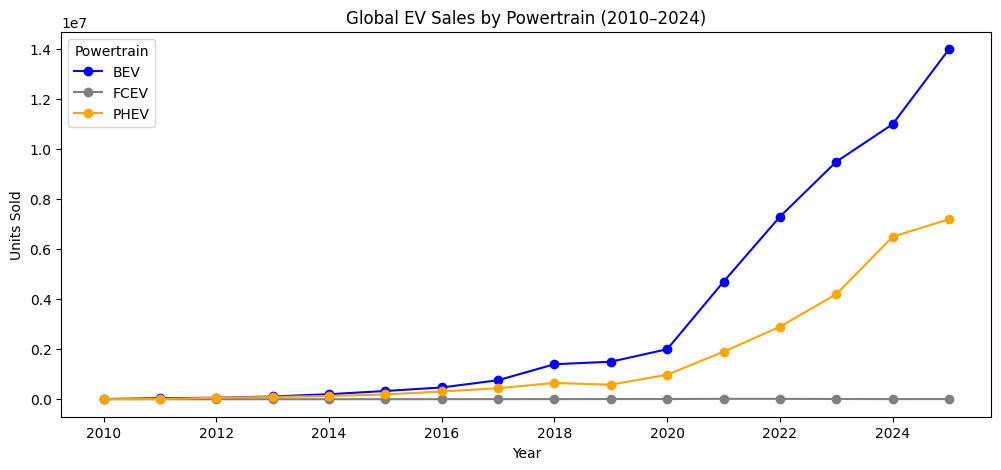

In [ ]:
world = df[(df['Region_Country'] == 'World') & (df['Category'] == 'Historical')]
pivot = world.groupby(['Year', 'Powertrain'])['EV_Sales_Cars'].sum().unstack()

pivot.plot(kind='line', figsize=(12,5),marker = 'o',
           color={'BEV':'Blue', 'PHEV':'Orange', 'FCEV':'Grey'})
plt.title('Global EV Sales by Powertrain (2010–2024)')
plt.ylabel('Units Sold')
plt.xlabel('Year')
plt.show()

#### Findings
* BEV has been dominating since 2013
* PHEV almost caught up with BEV in 2012

#### EDA: Market Share by Powertrain

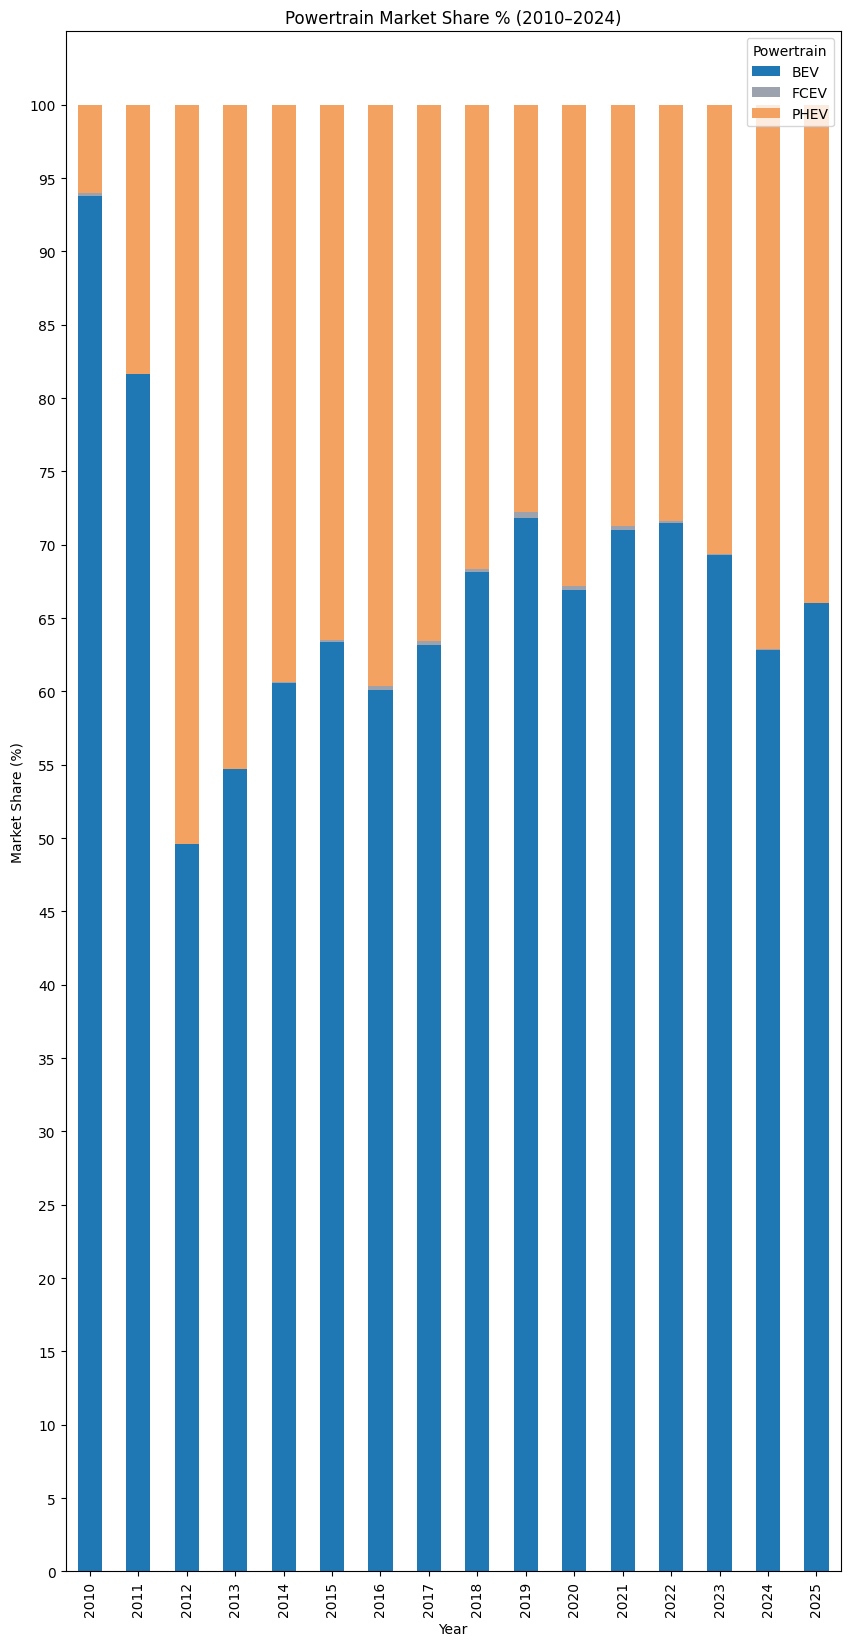

In [ ]:
share = pivot.div(pivot.sum(axis=1), axis=0) * 100

share.plot(kind='bar', stacked=True, figsize=(10,20),
           color={'BEV':'#1F77B4', 'PHEV':'#F4A261', 'FCEV':'#9CA3AF'})
plt.title('Powertrain Market Share % (2010–2024)')
plt.ylabel('Market Share (%)')
plt.yticks(range(0, 101, 5))
plt.show()

#### Findings
* FCEV is neglible (*** FCEV market share remains below 0.5% throughout 2010-2024 and not easily visible in the chart due small value)
* FCEV cannot be considered as mainstream technology.
* PHEV share dropped from 50% (2012) to 27% (2019) but recover to 37% by 2024

#### EDA 3: Regional breakdown

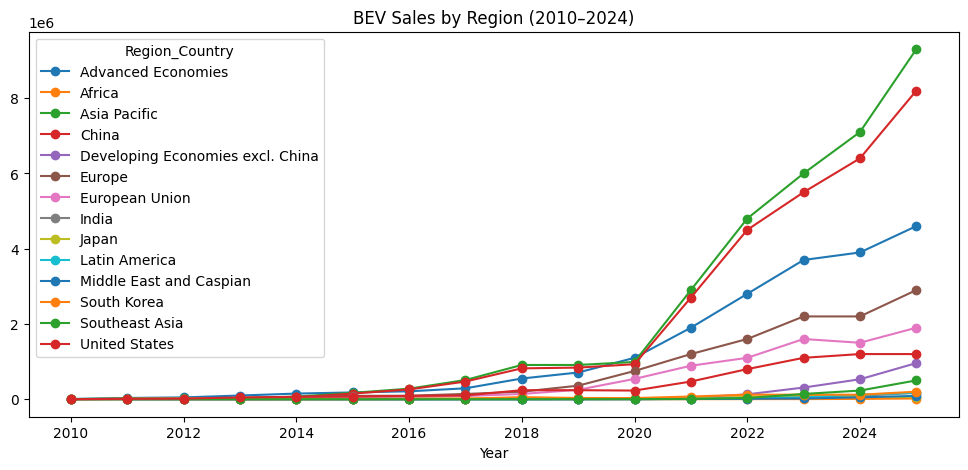

In [ ]:
regional_all_bev = df[(df['Geo_type'] == 'aggregate') &
                  (df['Category'] == 'Historical') &
                  (df['Powertrain'] == 'BEV') &
                  (df['Region_Country'] != 'World')]


pivot_r = regional_all_bev.groupby(['Year', 'Region_Country'])['EV_Sales_Cars'].sum().unstack()
pivot_r.plot(kind='line', figsize=(12,5), marker='o')
plt.title('BEV Sales by Region (2010–2024)')
plt.show()

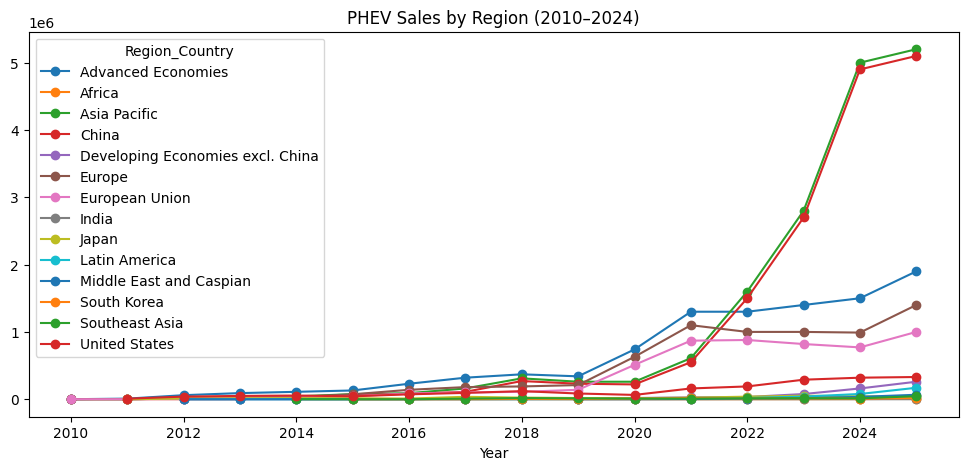

In [ ]:
regional_all_phev = df[(df['Geo_type'] == 'aggregate') &
                  (df['Category'] == 'Historical') &
                  (df['Powertrain'] == 'PHEV') &
                  (df['Region_Country'] != 'World')]



pivot_r = regional_all_phev.groupby(['Year', 'Region_Country'])['EV_Sales_Cars'].sum().unstack()
pivot_r.plot(kind='line', figsize=(12,5), marker='o')
plt.title('PHEV Sales by Region (2010–2024)')
plt.show()

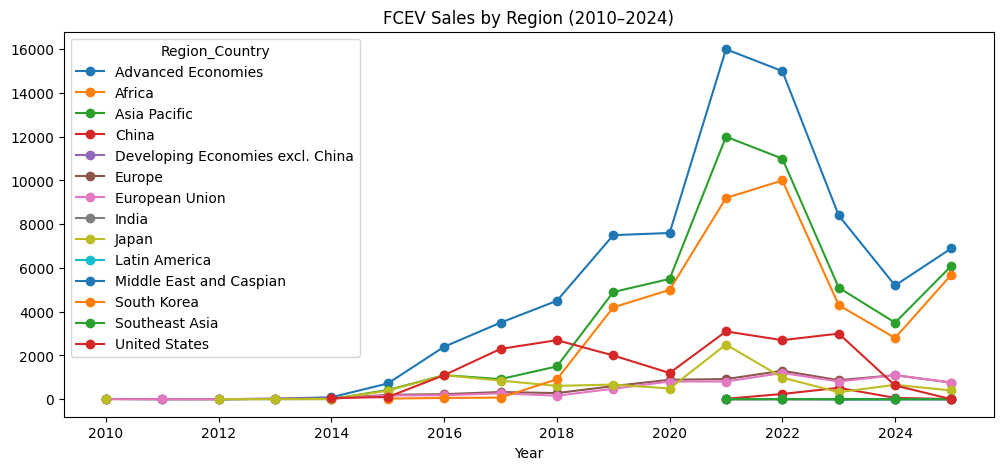

In [ ]:
regional_all_fcev = df[(df['Geo_type'] == 'aggregate') &
                  (df['Category'] == 'Historical') &
                  (df['Powertrain'] == 'FCEV') &
                  (df['Region_Country'] != 'World')]



pivot_r = regional_all_fcev.groupby(['Year', 'Region_Country'])['EV_Sales_Cars'].sum().unstack()
pivot_r.plot(kind='line', figsize=(12,5), marker='o')
plt.title('FCEV Sales by Region (2010–2024)')
plt.show()

#### EDA: BEV, PHEV, FCEV World Trend

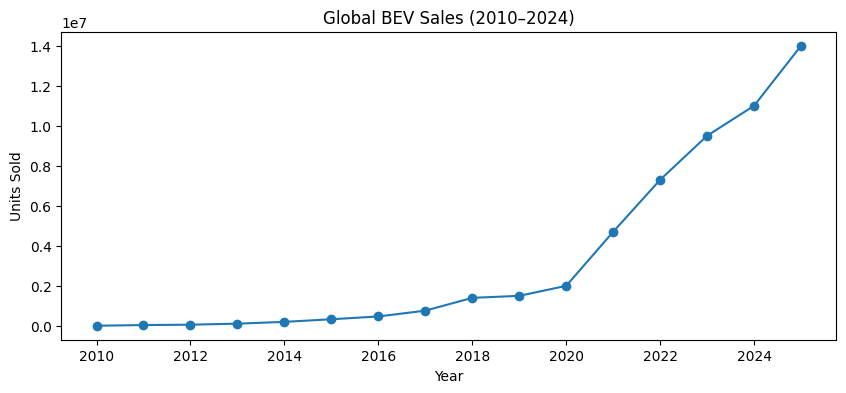

In [ ]:
bev = df[(df['Powertrain'] == 'BEV') &
          (df['Region_Country'] == 'World') &
          (df['Category'] == 'Historical')]
bev_world = bev.groupby('Year')['EV_Sales_Cars'].sum()

bev_world.plot(kind='line', marker='o', color='#1F77B4', figsize=(10,4))
plt.title('Global BEV Sales (2010–2024)')
plt.ylabel('Units Sold')
plt.show()

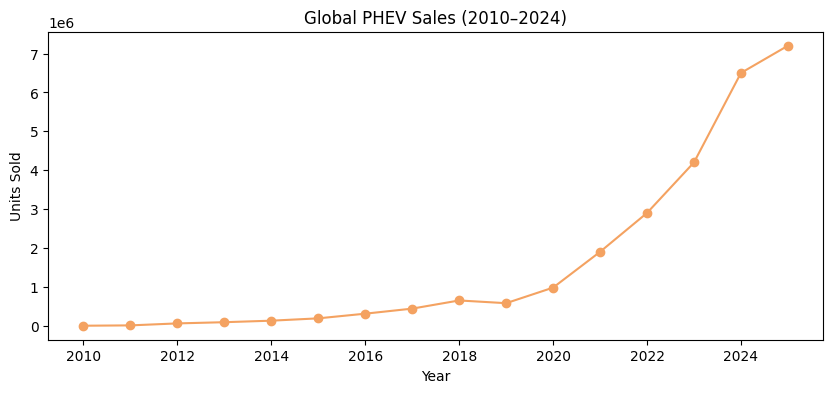

In [ ]:
phev = df[(df['Powertrain'] == 'PHEV') &
          (df['Region_Country'] == 'World') &
          (df['Category'] == 'Historical')]
phev_world = phev.groupby('Year')['EV_Sales_Cars'].sum()

phev_world.plot(kind='line', marker='o', color='#F4A261', figsize=(10,4))
plt.title('Global PHEV Sales (2010–2024)')
plt.ylabel('Units Sold')
plt.show()

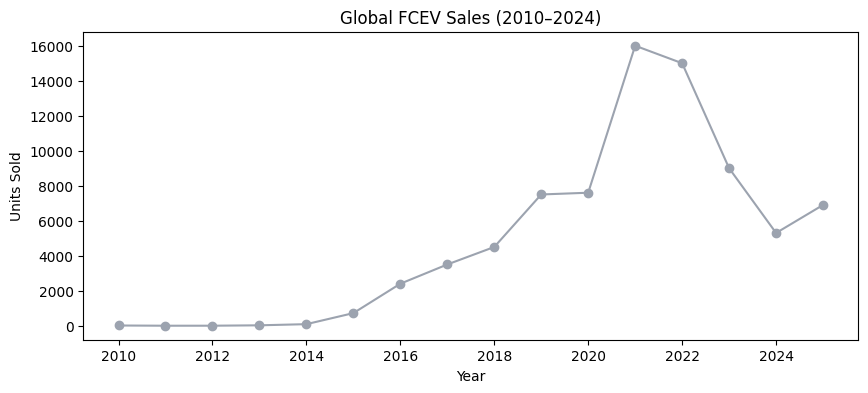

In [ ]:
fcev = df[(df['Powertrain'] == 'FCEV') &
          (df['Region_Country'] == 'World') &
          (df['Category'] == 'Historical')]
fcev_world = fcev.groupby('Year')['EV_Sales_Cars'].sum()

fcev_world.plot(kind='line', marker='o', color='#9CA3AF', figsize=(10,4))
plt.title('Global FCEV Sales (2010–2024)')
plt.ylabel('Units Sold')
plt.show()